<a href="https://colab.research.google.com/github/Ophelie4/pfizer-document-intelligence/blob/main/project-04-ocr-comparison-and-layout-extraction/notebooks/Ophelie_OCR_Engine_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OCR Engine Comparison: Tesseract vs PaddleOCR vs EasyOCR

Comparing three OCR engines on the same scanned pharmaceutical document: **Certificate of Quality (Pharmaceutical SDF - Page 3)**.

Goal: not to declare a "winner" outright, but to observe how each engine handles the same document and note practical trade-offs (accuracy, layout preservation, setup friction, usability for downstream automation).

In [ ]:
# --- Setup: system + python packages ---
!apt-get -qq update > /dev/null
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip install -q pytesseract pymupdf opencv-python-headless gdown
print("Base packages installed.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 68.7 MB/s eta 0:00:00
Base packages installed.


In [ ]:
# EasyOCR install
!pip install -q easyocr
print("EasyOCR installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 76.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 19.0 MB/s eta 0:00:00
EasyOCR installed.


In [ ]:
# PaddleOCR install (paddlepaddle CPU + paddleocr)
!pip install -q paddlepaddle paddleocr
print("PaddleOCR installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 767.5/767.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1

In [ ]:
import re, json, cv2, numpy as np, gdown, fitz, pytesseract
from pytesseract import Output
from matplotlib import pyplot as plt

# Download the Certificate of Quality PDF (pharmaceutical-sdf-page3-certificate-quality.pdf)
file_id = "1rdrWYitqKV76NhYAJ-prNc43-EiCNxOV"
url = f"https://drive.google.com/uc?id={file_id}"
gdown.download(url, "sdf_page3.pdf", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1rdrWYitqKV76NhYAJ-prNc43-EiCNxOV
To: /content/sdf_page3.pdf
100%|██████████| 83.9k/83.9k [00:00<00:00, 15.3MB/s]


'sdf_page3.pdf'

Page rendered to image: (3300, 2550, 3)


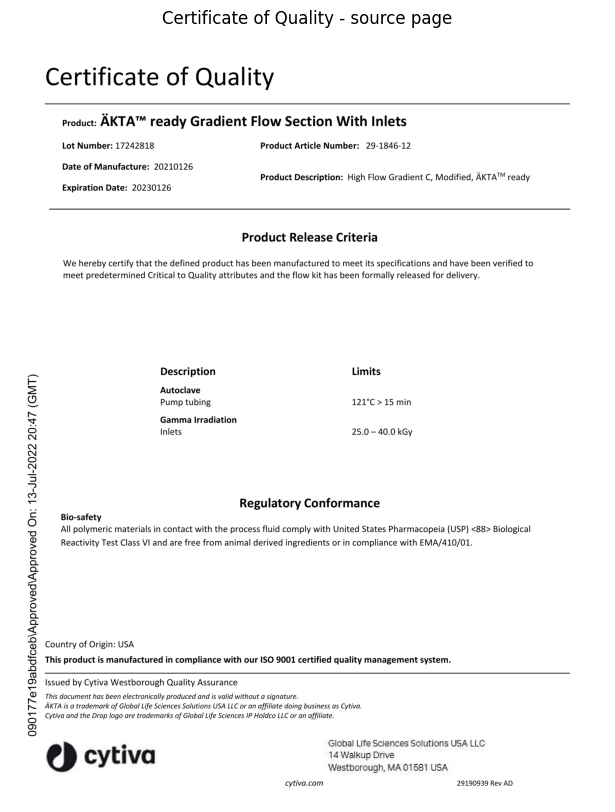

In [ ]:
# Convert PDF page to a high-res image using PyMuPDF (avoids poppler-utils dependency)
pdf_doc = fitz.open("sdf_page3.pdf")
page0 = pdf_doc[0]
pix = page0.get_pixmap(matrix=fitz.Matrix(300 / 72, 300 / 72))
arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
img = cv2.cvtColor(arr, cv2.COLOR_RGBA2BGR) if pix.n == 4 else cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)
cv2.imwrite("sdf_page3.png", img)
print("Page rendered to image:", img.shape)

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Certificate of Quality - source page")
plt.show()

## 1. Tesseract OCR

In [ ]:
# --- Tesseract ---
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tesseract_text = pytesseract.image_to_string(gray)
print("=== Tesseract raw text ===")
print(tesseract_text)

with open("tesseract_output.txt", "w") as f:
    f.write(tesseract_text)

=== Tesseract raw text ===
090177e19abdfceb\Approved\Approved On: 13-Jul-2022 20:47 (GMT)

Certificate of Quality

Product: AKTA™ ready Gradient Flow Section With Inlets

Lot Number: 17242818 Product Article Number: 29-1846-12
Date of Manufacture: 20210126

Product Description: High Flow Gradient C, Modified, AKTA™ ready
Expiration Date: 20230126

Product Release Criteria

We hereby certify that the defined product has been manufactured to meet its specifications and have been verified to
meet predetermined Critical to Quality attributes and the flow kit has been formally released for delivery.

Description Limits
Autoclave
Pump tubing 121°C > 15 min

Gamma Irradiation
Inlets 25.0 — 40.0 kGy

Regulatory Conformance
Bio-safety
All polymeric materials in contact with the process fluid comply with United States Pharmacopeia (USP) <88> Biological
Reactivity Test Class VI and are free from animal derived ingredients or in compliance with EMA/410/01.

Country of Origin: USA

This product is 

Tesseract confident words: 218


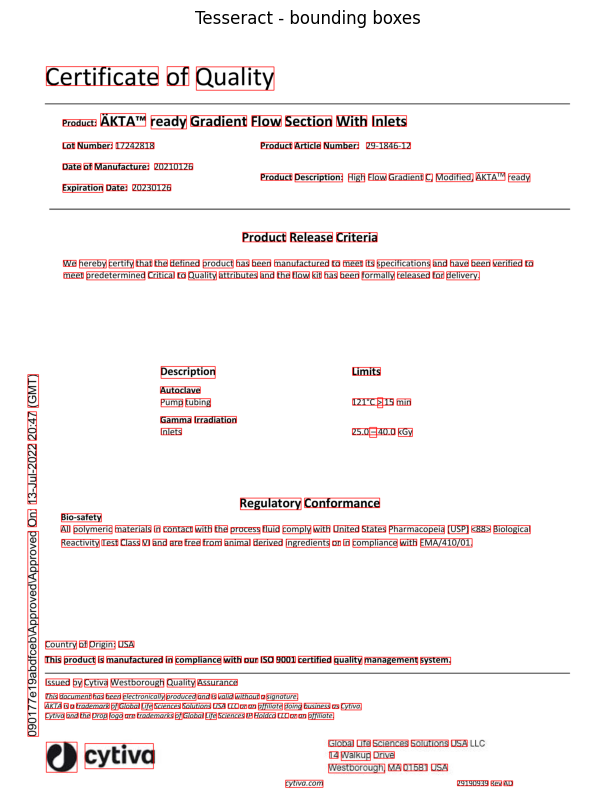

In [ ]:
# Tesseract word-level boxes + confidence, draw bounding boxes
data = pytesseract.image_to_data(gray, output_type=Output.DICT)
tesseract_img = img.copy()
tess_words = []
for i in range(len(data["text"])):
    word = data["text"][i].strip()
    conf = int(data["conf"][i]) if data["conf"][i] != "-1" else -1
    if word and conf > 30:
        x, y, w, h = data["left"][i], data["top"][i], data["width"][i], data["height"][i]
        tess_words.append({"text": word, "conf": conf, "bbox": [x, y, x+w, y+h]})
        cv2.rectangle(tesseract_img, (x, y), (x+w, y+h), (0, 0, 255), 2)

cv2.imwrite("tesseract_annotated.png", tesseract_img)
print(f"Tesseract confident words: {len(tess_words)}")

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(tesseract_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Tesseract - bounding boxes")
plt.show()

## 2. EasyOCR

In [ ]:
# --- EasyOCR ---
import easyocr

reader = easyocr.Reader(["en"], gpu=False)
easyocr_results = reader.readtext("sdf_page3.png")

easyocr_text_lines = [r[1] for r in easyocr_results]
easyocr_text = "\n".join(easyocr_text_lines)
print("=== EasyOCR raw text ===")
print(easyocr_text)

with open("easyocr_output.txt", "w") as f:
    f.write(easyocr_text)

print(f"\nEasyOCR detected {len(easyocr_results)} text regions")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


=== EasyOCR raw text ===
Certificate of Quality
Product:
AKTA
TM
ready Gradient Flow Section With Inlets
Lot Number: 17242818
Product Article Number:
29-1846-12
Date of Manufacture: 20210126
Product Description: High Flow Gradient C, Modified, AKTATM ready
Expiration Date: 20230126
Product Release Criteria
We hereby certify that the defined product has been manufactured to meet its specifications and have been verified to
meet predetermined Critical to Quality attributes and the flow kit has been formally released for delivery:
Description
Limits
5
Autoclave
Pump tubing
121*C > 15 min
Gamma Irradiation
8
Inlets
25.0
_
40.0 kGy
1
Regulatory Conformance
8
Bio-safety
All polymeric materials in contact with the process fluid comply with United States Pharmacopeia (USP) <88> Biological
Reactivity Test Class VI and are free from animal derived ingredients or in compliance with EMA/410/01.
L
Cburprodt Griginaustactured
in compliance with our ISO 9001 certified quality management system.
Issue

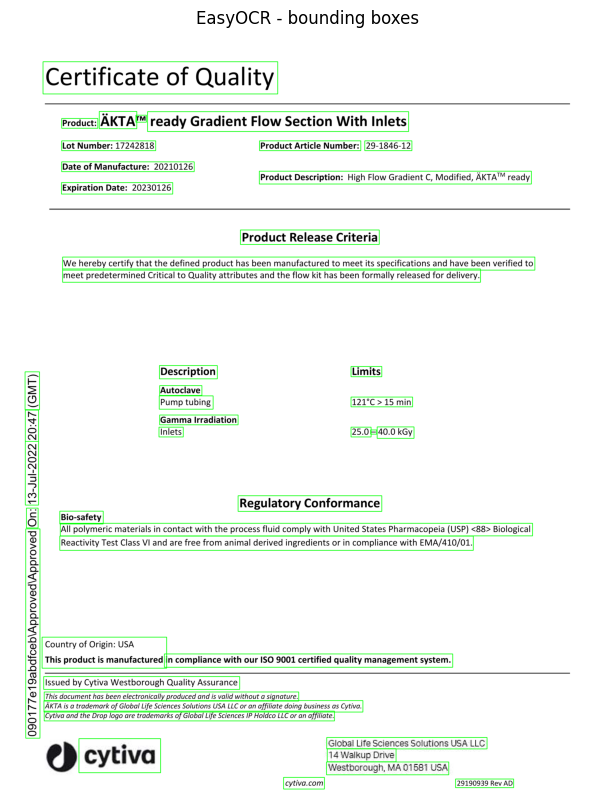

In [ ]:
# Draw EasyOCR bounding boxes
easyocr_img = img.copy()
easyocr_json = []
for (bbox, text, conf) in easyocr_results:
    pts = np.array(bbox, dtype=np.int32)
    cv2.polylines(easyocr_img, [pts], isClosed=True, color=(0, 255, 0), thickness=2)
    easyocr_json.append({"text": text, "conf": round(float(conf), 3), "bbox": [[int(p[0]), int(p[1])] for p in bbox]})

cv2.imwrite("easyocr_annotated.png", easyocr_img)

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(easyocr_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("EasyOCR - bounding boxes")
plt.show()

## 3. PaddleOCR

In [ ]:
# --- PaddleOCR ---
from paddleocr import PaddleOCR

paddle_ocr = PaddleOCR(
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    enable_mkldnn=False,
    lang="en",
)
paddle_result = paddle_ocr.predict("sdf_page3.png")

paddle_lines = []
for res in paddle_result:
    d = res if isinstance(res, dict) else dict(res)
    texts = d.get("rec_texts", [])
    scores = d.get("rec_scores", [])
    polys = d.get("rec_polys", d.get("dt_polys", []))
    for t, s, p in zip(texts, scores, polys):
        paddle_lines.append({"text": t, "conf": round(float(s), 3), "bbox": [[int(pt[0]), int(pt[1])] for pt in p]})

paddle_text = "\n".join([l["text"] for l in paddle_lines])
print("=== PaddleOCR raw text ===")
print(paddle_text)

with open("paddleocr_output.txt", "w") as f:
    f.write(paddle_text)

print(f"\nPaddleOCR detected {len(paddle_lines)} lines")

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


=== PaddleOCR raw text ===
Certificate of Quality
Product: ÄKTA™ ready Gradient Flow Section With Inlets
Lot Number: 17242818
Product Article Number: 29-1846-12
Date of Manufacture: 20210126
Product Description: High Flow Gradient C, Modified, ÄKTAT™ ready
Expiration Date: 20230126
Product Release Criteria
We hereby certify that the defined product has been manufactured to meet its specifications and have been verified to
meet predetermined Critical to Quality attributes and the flow kit has been formally released for delivery.
Description
Limits
90:T)
Autoclave
Pump tubing
121°C > 15 min
Gamma Irradiation
Inlets
25.0 – 40.0 kGy
Regulatory Conformance
Bio-safety
All polymeric materials in contact with the process fluid comply with United States Pharmacopeia (USP) <88> Biological
Reactivity Test Class VI and are free from animal derived ingredients or in compliance with EMA/410/01.
Country of Origin: USA
This product is manufactured in compliance with our ISO 9001 certified quality mana

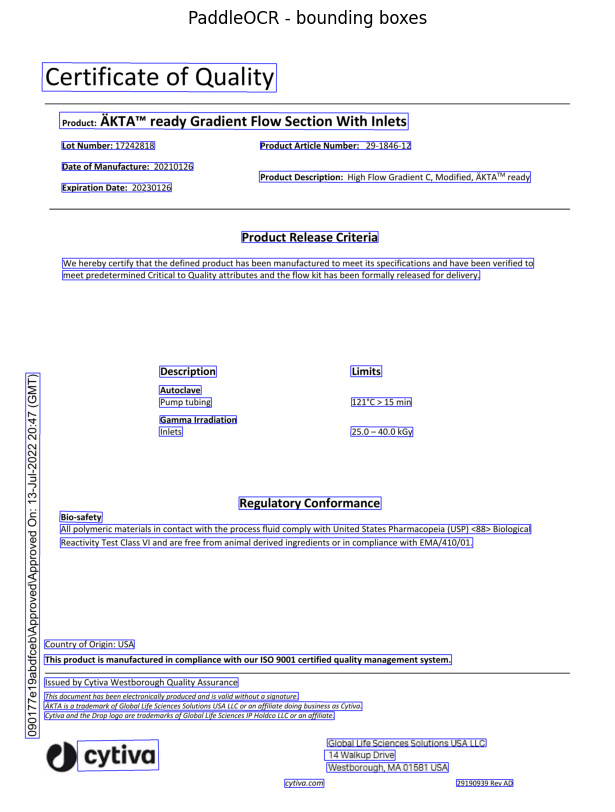

In [ ]:
# Draw PaddleOCR bounding boxes
paddle_img = img.copy()
for l in paddle_lines:
    pts = np.array(l["bbox"], dtype=np.int32)
    cv2.polylines(paddle_img, [pts], isClosed=True, color=(255, 0, 0), thickness=2)

cv2.imwrite("paddleocr_annotated.png", paddle_img)

plt.figure(figsize=(8,10))
plt.imshow(cv2.cvtColor(paddle_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("PaddleOCR - bounding boxes")
plt.show()

## 4. Side-by-side comparison

In [ ]:
# Quick keyword search across all 3 outputs for key fields
keywords = ["lot", "vendor", "expir", "certificate", "quality", "date"]

def keyword_hits(text, keywords):
    text_low = text.lower()
    return {kw: (kw in text_low) for kw in keywords}

comparison = {
    "Tesseract": {"char_count": len(tesseract_text), "keyword_hits": keyword_hits(tesseract_text, keywords)},
    "EasyOCR": {"char_count": len(easyocr_text), "keyword_hits": keyword_hits(easyocr_text, keywords)},
    "PaddleOCR": {"char_count": len(paddle_text), "keyword_hits": keyword_hits(paddle_text, keywords)},
}

print(json.dumps(comparison, indent=2))

with open("ocr_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

{
  "Tesseract": {
    "char_count": 1507,
    "keyword_hits": {
      "lot": true,
      "vendor": false,
      "expir": true,
      "certificate": true,
      "quality": true,
      "date": true
    }
  },
  "EasyOCR": {
    "char_count": 1411,
    "keyword_hits": {
      "lot": true,
      "vendor": false,
      "expir": true,
      "certificate": true,
      "quality": true,
      "date": true
    }
  },
  "PaddleOCR": {
    "char_count": 1429,
    "keyword_hits": {
      "lot": true,
      "vendor": false,
      "expir": true,
      "certificate": true,
      "quality": true,
      "date": true
    }
  }
}


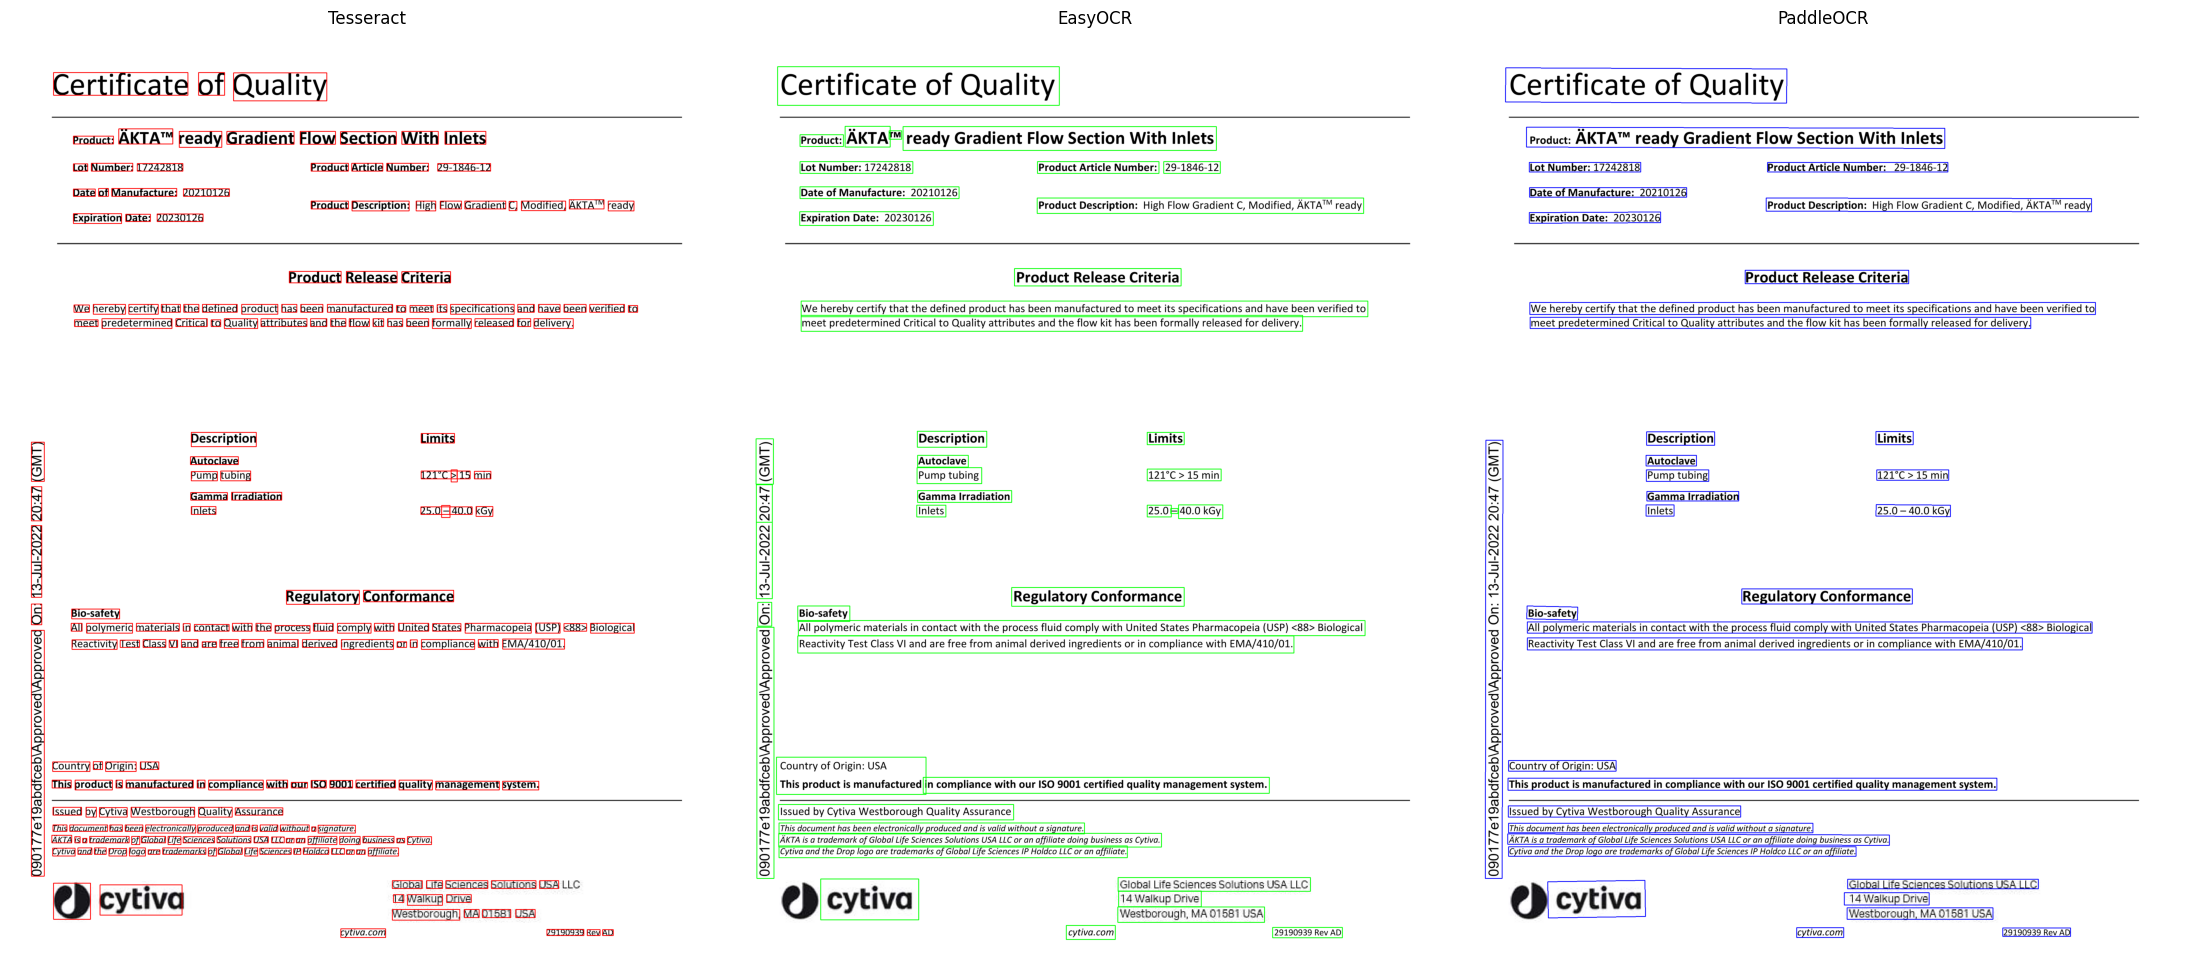

Saved side-by-side comparison: ocr_side_by_side.png


In [ ]:
# Save all three annotated images side-by-side for visual inspection
fig, axes = plt.subplots(1, 3, figsize=(22, 12))
titles = ["Tesseract", "EasyOCR", "PaddleOCR"]
images = [tesseract_img, easyocr_img, paddle_img]
for ax, title, im in zip(axes, titles, images):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("ocr_side_by_side.png", dpi=150)
plt.show()
print("Saved side-by-side comparison: ocr_side_by_side.png")

## Summary of findings

- **Tesseract**: fastest to set up (just an apt-get install), output is plain text with no layout structure — line breaks depend heavily on the raw scan quality.
- **EasyOCR**: pip-installable, no system dependency, returns per-line bounding polygons + confidence scores out of the box, generally handles printed form layouts well.
- **PaddleOCR**: heaviest install (paddlepaddle + paddleocr, larger download and longer cold-start to load detection/recognition/angle-classification models), but tends to preserve reading order and grouped text blocks better than the other two.

Detailed findings, side-by-side visual inspection, and recommendation are written up in the accompanying Google Doc report.